# 3 · Capital structure and cash holdings across countries
How much do firms borrow, how much cash do they hold, and do the textbook determinants work everywhere? The leverage model follows Rajan & Zingales (1995): firms with more **tangible** assets borrow more, more **profitable** firms borrow less (pecking order) and **larger** firms borrow more. The cash model follows Opler et al. (1999). Both are estimated with firm and year fixed effects, separately by region, so each coefficient measures how a firm's own leverage or cash changes as its characteristics change.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


In [2]:
cs = aggregate.summary(p.assign(lev=100 * p.leverage, cash_=100 * p.cash, tang=100 * p.tangibility), "loc", ["lev", "cash_", "tang"], min_firms=30)
cs.columns = ["leverage %", "cash %", "tangibility %", "firms", "firm_years"]
cs["region"] = p.groupby("loc")["region"].first().reindex(cs.index)
gdp = p.groupby("loc")["gdp_pc"].median()
cs["GDP per capita (USD, 2015 prices)"] = gdp.reindex(cs.index).round(0)
cs.round(1).to_csv(DATA / "capital_structure_by_country.csv")
reg = aggregate.summary(p.assign(lev=100 * p.leverage, cash_=100 * p.cash, net=100 * (p.leverage - p.cash)), "region", ["lev", "cash_", "net"], min_firms=30).reindex(REG_ORDER)
reg.columns = ["leverage %", "cash %", "net debt % of assets", "firms", "firm_years"]
reg.round(1)

,leverage %,cash %,net debt % of assets,firms,firm_years
region,,,,,
North America,21.2,9.9,10.2,13908,117385
Western Europe,19.0,9.5,9.1,8453,94514
Japan,16.9,15.6,1.2,4261,58598
Other developed Asia-Pacific,16.2,16.0,0.2,9465,113375
China,15.4,17.6,-1.7,4704,58149
India,27.3,3.0,22.3,3673,54194
OIC members,19.7,7.0,11.3,3511,48831
Other emerging,19.4,6.5,11.7,4817,62753


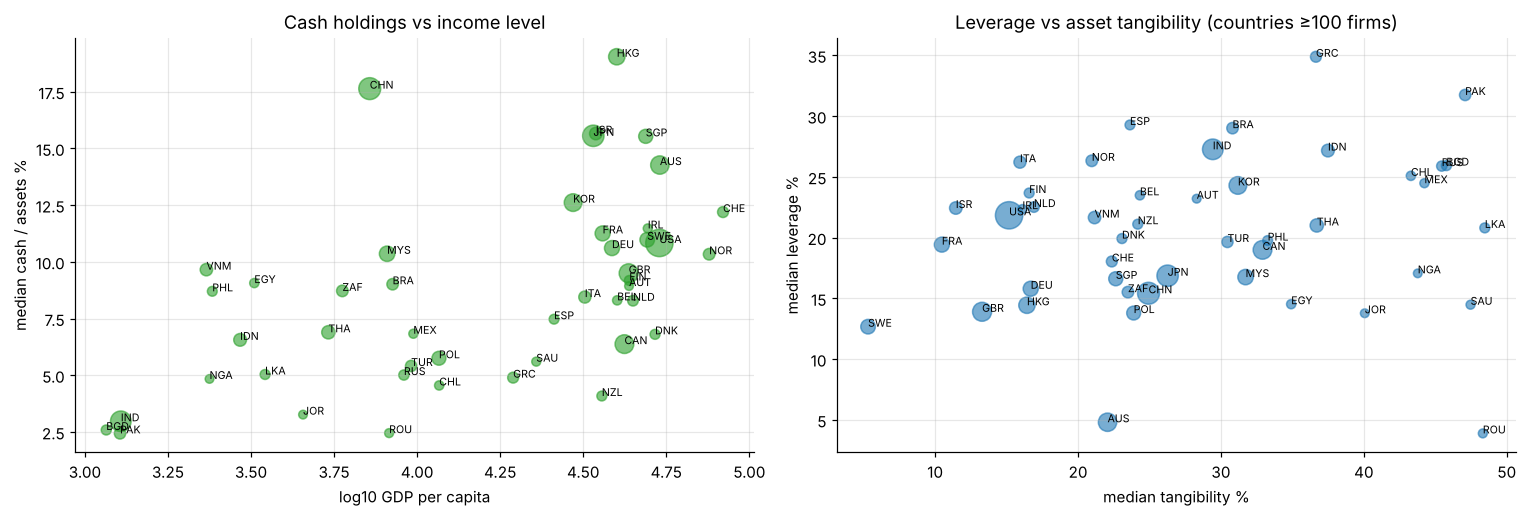

cross-country correlation, cash vs log GDP per capita: 0.52 | leverage vs tangibility: 0.14


In [3]:
big = cs[cs.firms >= 100].dropna()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(np.log10(big["GDP per capita (USD, 2015 prices)"]), big["cash %"], s=np.sqrt(big.firms) * 3, alpha=0.6, color="C2")
for c, r_ in big.iterrows(): ax[0].annotate(c, (np.log10(r_["GDP per capita (USD, 2015 prices)"]), r_["cash %"]), fontsize=7)
ax[0].set_xlabel("log10 GDP per capita"); ax[0].set_ylabel("median cash / assets %"); ax[0].set_title("Cash holdings vs income level")
ax[1].scatter(big["tangibility %"], big["leverage %"], s=np.sqrt(big.firms) * 3, alpha=0.6)
for c, r_ in big.iterrows(): ax[1].annotate(c, (r_["tangibility %"], r_["leverage %"]), fontsize=7)
ax[1].set_xlabel("median tangibility %"); ax[1].set_ylabel("median leverage %"); ax[1].set_title("Leverage vs asset tangibility (countries ≥100 firms)")
plt.tight_layout(); plt.savefig(IMG / "capital_structure_countries.png", bbox_inches="tight"); plt.show()
print("cross-country correlation, cash vs log GDP per capita:", round(np.corrcoef(np.log(big["GDP per capita (USD, 2015 prices)"]), big["cash %"])[0, 1], 2),
      "| leverage vs tangibility:", round(np.corrcoef(big["tangibility %"], big["leverage %"])[0, 1], 2))

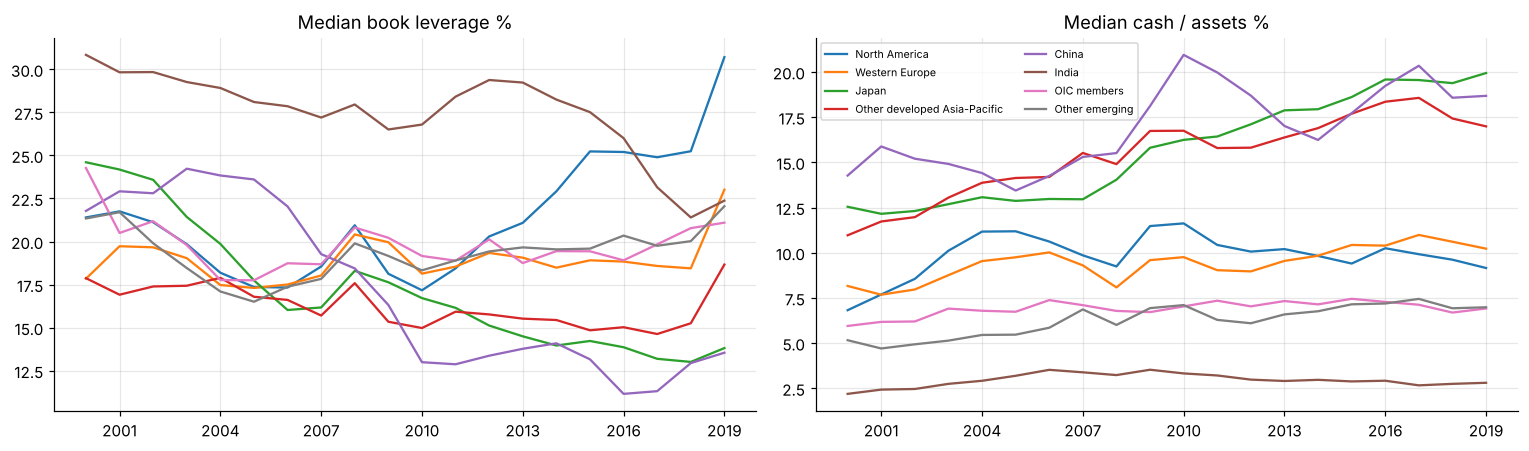

,leverage 2000,leverage 2019,cash 2000,cash 2019
region,,,,
North America,21.4,30.7,6.8,9.2
Western Europe,17.8,23.0,8.2,10.2
Japan,24.6,13.8,12.5,19.9
Other developed Asia-Pacific,17.9,18.7,11.0,17.0
China,21.8,13.5,14.3,18.7
India,30.8,22.4,2.2,2.8
OIC members,24.3,21.1,5.9,6.9
Other emerging,21.3,22.1,5.2,7.0


In [4]:
ty = p[p.fyear <= 2019].groupby(["fyear", "region"])[["leverage", "cash"]].median().unstack()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
(100 * ty["leverage"][REG_ORDER]).plot(ax=ax[0], legend=False); ax[0].set_title("Median book leverage %")
(100 * ty["cash"][REG_ORDER]).plot(ax=ax[1]); ax[1].set_title("Median cash / assets %"); ax[1].legend(fontsize=7, ncol=2); int_years(*ax)
plt.tight_layout(); plt.savefig(IMG / "leverage_cash_trends.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"leverage 2000": 100 * ty["leverage"].loc[2000], "leverage 2019": 100 * ty["leverage"].loc[2019],
              "cash 2000": 100 * ty["cash"].loc[2000], "cash 2019": 100 * ty["cash"].loc[2019]}).reindex(REG_ORDER).round(1)

## Determinants of leverage and cash (firm and year fixed effects)

In [5]:
X_LEV = ["tangibility", "roa", "size", "sales_growth"]
X_CASH = ["size", "roa", "sales_growth", "capex", "leverage", "rd"]
rows = []
for reg_ in REG_ORDER:
    sub = p[p.region == reg_]
    for y, xs in [("leverage", X_LEV), ("cash", X_CASH)]:
        res = regress.fe(sub, y, xs)
        for x in xs:
            rows.append({"region": reg_, "model": y, "variable": x, "coef": res.loc[x, "coef"], "t": res.loc[x, "t"], "N": res.attrs["nobs"]})
fe = pd.DataFrame(rows); fe.round(4).to_csv(DATA / "leverage_cash_fe.csv", index=False)
lev = fe[fe.model == "leverage"].pivot(index="region", columns="variable", values="coef").reindex(REG_ORDER)[X_LEV]
levt = fe[fe.model == "leverage"].pivot(index="region", columns="variable", values="t").reindex(REG_ORDER)[X_LEV]
print("Leverage model: coefficients (t-statistics in the next table)"); display(lev.map(lambda v: f"{v:.3f}")); levt.round(1)

Leverage model: coefficients (t-statistics in the next table)


variable,tangibility,roa,size,sales_growth
region,,,,
North America,0.240,-0.159,-0.039,-0.004
Western Europe,0.253,-0.180,-0.003,-0.002
Japan,0.279,-0.444,0.055,0.008
Other developed Asia-Pacific,0.168,-0.178,-0.004,0.001
China,0.218,-0.295,0.026,0.002
India,0.266,-0.510,-0.010,-0.001
OIC members,0.182,-0.425,0.015,0.003
Other emerging,0.178,-0.285,0.010,-0.002


variable,tangibility,roa,size,sales_growth
region,,,,
North America,12.6,-16.5,-11.1,-3.2
Western Europe,14.5,-15.6,-0.9,-2.2
Japan,13.4,-13.9,12.2,2.4
Other developed Asia-Pacific,15.4,-19.0,-1.2,1.2
China,13.5,-12.7,8.6,1.1
India,12.9,-19.4,-2.4,-1.0
OIC members,10.1,-17.7,3.0,1.7
Other emerging,11.5,-14.6,2.2,-1.2


In [6]:
cash = fe[fe.model == "cash"].pivot(index="region", columns="variable", values="coef").reindex(REG_ORDER)[X_CASH]
casht = fe[fe.model == "cash"].pivot(index="region", columns="variable", values="t").reindex(REG_ORDER)[X_CASH]
print("Cash model: coefficients"); display(cash.map(lambda v: f"{v:.3f}")); casht.round(1)

Cash model: coefficients


variable,size,roa,sales_growth,capex,leverage,rd
region,,,,,,
North America,-0.024,0.033,0.000,-0.207,-0.110,0.034
Western Europe,-0.018,0.025,0.001,-0.171,-0.126,0.026
Japan,-0.013,0.091,-0.012,-0.273,-0.129,0.018
Other developed Asia-Pacific,-0.034,-0.016,0.004,-0.205,-0.171,0.019
China,0.001,-0.026,0.000,-0.208,-0.256,-0.042
India,-0.008,0.037,0.002,-0.025,-0.070,0.007
OIC members,-0.007,0.041,0.001,-0.109,-0.097,0.021
Other emerging,-0.005,0.048,0.002,-0.111,-0.104,0.056


variable,size,roa,sales_growth,capex,leverage,rd
region,,,,,,
North America,-14.3,7.9,0.6,-14.7,-23.4,13.8
Western Europe,-9.7,3.5,1.3,-11.7,-20.0,5.6
Japan,-4.1,5.2,-4.5,-14.7,-14.1,0.9
Other developed Asia-Pacific,-19.3,-2.9,5.5,-15.5,-26.4,4.6
China,0.6,-2.3,0.4,-13.8,-25.3,-2.5
India,-5.2,3.8,1.9,-3.1,-14.4,0.8
OIC members,-2.9,4.1,1.1,-8.6,-14.8,0.9
Other emerging,-2.5,4.6,2.1,-9.3,-16.5,2.4


## Findings
* **Indian firms are the most indebted and hold the least cash.** Median book leverage is 27% of assets, against 15-21% elsewhere, and cash is 3% of assets, so net debt is 22% of assets. Japanese, Chinese and other developed Asia-Pacific firms hold roughly as much cash as debt (net debt near zero).
* **Cash holdings rise with national income** (cross-country correlation 0.52 with log GDP per capita). Hong Kong, China, Japan and Singapore stand out with 15-19% of assets in cash. Leverage is only weakly related to asset tangibility *across* countries (correlation 0.14): institutions and bank systems differ too much.
* **Two decades of deleveraging in Asia, re-leveraging in North America.** From 2000 to 2019 median leverage fell from 25% to 14% in Japan and from 22% to 14% in China while cash rose. In North America leverage rose from 21% to 31%, part of it in 2019 itself, the first year that operating leases were brought onto balance sheets (ASC 842 and IFRS 16). The same jump is visible in Western Europe and other IFRS markets.
* **The textbook determinants hold within firms everywhere.** In every region, more tangible assets mean more debt (+0.17 to +0.28 per unit of tangibility, t > 10), and more profitable firms borrow less (-0.16 to -0.51, t > 12), consistent with the pecking order. Size has no consistent within-firm effect: positive in Japan and China, negative in North America.
* **Cash holdings fall with leverage and investment** (leverage -0.07 to -0.26, capex -0.03 to -0.27) and rise with R&D in the developed markets, the precautionary motive of Opler et al. (1999). They fall with size in most regions: larger firms need less of a buffer.